# MedBhasha — Bengali Clinical NLP: Annotate → NER → Cluster → Retrieve
**Team JUSL Health Home · COMSYS Hackathon-8 · Round 2 notebook**

One notebook, three stages, fully offline and deterministic (seed 42, no external API, no web retrieval, no model downloads):

| Stage | What this notebook does | Output files (`outputs/`) |
|---|---|---|
| 0 · Data | Loads our own annotated corpus (BIO), re-runs the official `validate.py`, EDA | `eda_*.csv`, `figures/eda_*.png` |
| 1 · NER | Lexicon-augmented, section-aware CRF; cross-validation + ablations; predictions for the released notes | `ner_predictions_bio.csv`, `ner_predictions_spans.csv`, `ner_predictions.jsonl`, `ner_cv_*.csv` |
| 2 · Clustering | Unsupervised phenotype clusters from NER output; frequency & relationship analysis | `clusters.csv`, `cluster_summary.csv`, `cluster_selection.csv`, `test_*pairs.csv` |
| 3 · RAG | Retrieval over our annotated notes + grounded extractive answers for the 30 queries and a live-query cell | `rag_answers.{csv,jsonl,md}`, `rag_answers_team_corpus_only.*` |

**Run:** `pip install -r requirements.txt` then *Kernel → Restart & Run All* (≈ 6 min on 4 CPU cores).
Read `docs/TECHNICAL_REPORT.md` for the reasoning.

In [1]:
import os, sys, json, time, subprocess
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd
from IPython.display import display, Image, Markdown
pd.set_option("display.max_colwidth", 140, "display.width", 200)

from medbhasha import pipeline, corpus, analysis, cluster, run_all
from medbhasha.config import SEED, OUT, R1, R2, ENTITY_TYPES
from medbhasha.tokenizer import tokenize
print("repo root:", ROOT, "| seed:", SEED)

repo root: /home/user/medbhasa_hackathon | seed: 42


## 0 · Data: our annotated corpus (Round 1, expanded)

The organisers asked us (after Round 1) to grow the corpus to ≈ 10 000 annotated tokens and to prioritise rare entity types.
We kept the 40 Round-1 notes (with 8 documented consistency fixes, `round1_deliverables/round1_fixes_log.tsv`) and added 192 new
team-authored synthetic notes (source and annotation method: `round1_deliverables/SOURCE_DECLARATION.md`).
Annotation sources are human-readable span markup under `data/round1/annotation_sources/`; `scripts/build_corpus.py` aligns them to tokens and writes the BIO CSV.

In [2]:
notes, meta, raw = pipeline.load_train()
n_tok = sum(len(t) for t, _ in notes.values())
print(f"notes: {len(notes)}   tokens: {n_tok}   domains: {meta.domain.nunique()}")

# official validator (mandatory part of the submission)
r = subprocess.run([sys.executable, "resources/validate.py", "--input", str(R1 / "annotated_corpus.csv"),
                    "--scheme", "BIO", "--report", "round1_deliverables/validation_report.txt"],
                   capture_output=True, text=True)
print(r.stdout[-420:])

notes: 232   tokens: 12060   domains: 23
TOM                   603
   TEMPORAL                  377
   TEST                      343
   MEDICATION                332
   BODY_SITE                 263
   DOSAGE                    262
   TEST_RESULT               255
   DIAGNOSIS                 231
   NEGATION_UNCERTAINTY      160
   PROCEDURE                 73

PASSED — see round1_deliverables/validation_report.txt for full details.
Errors: 0 | Warnings: 0



In [3]:
def show(nid, notes=notes):
    toks, tags = notes[nid]
    out, i = [], 0
    for s, e, ty in corpus.spans_from_bio(tags):
        out += toks[i:s]
        out.append("[" + " ".join(toks[s:e]) + "]{" + ty + "}")
        i = e
    return " ".join(out + toks[i:])

for nid in ("n005", "n052", "n224"):
    print(nid, "→", show(nid), "\n")

n005 → রোগীর [ডায়াবেটিস]{DIAGNOSIS} আছে । [সকালে]{TEMPORAL} উপবাসে [রক্তে শর্করা]{TEST} [১৮০]{TEST_RESULT} এসেছে , তিনি [মেটফরমিন]{MEDICATION} [৫০০ মিগ্রা দিনে দুইবার]{DOSAGE} নিচ্ছেন । 

n052 → ৫৫ বছর বয়সী পুরুষ রোগী । রোগী জানান , [গতকাল রাত থেকে]{TEMPORAL} [বাম পায়ের বুড়ো আঙুলে]{BODY_SITE} [তীব্র ব্যথা]{SYMPTOM} , [ফোলা]{SYMPTOM} ও [লালচে ভাব]{SYMPTOM} , [জ্বর]{SYMPTOM} [নেই]{NEGATION_UNCERTAINTY} । পূর্ব ইতিহাস : মাংস ও অ্যালকোহল বেশি খাওয়ার অভ্যাস । [সিরাম ইউরিক অ্যাসিড]{TEST} [৯.৮ মি.গ্রা./ডেসিলিটার]{TEST_RESULT} । রোগ নির্ণয় : [গাউট]{DIAGNOSIS} । চিকিৎসা : [ইন্ডোমেথাসিন]{MEDICATION} [২৫ মি.গ্রা. দিনে ৩ বার]{DOSAGE} [৫ দিন]{TEMPORAL} ; [কোলচিসিন]{MEDICATION} [০.৫ মি.গ্রা. দিনে ২ বার]{DOSAGE} । পরামর্শ : লাল মাংস ও অ্যালকোহল বাদ দিন , প্রচুর পানি পান করুন । ফলোআপ : [২ সপ্তাহ পর]{TEMPORAL} । 

n224 → ৩০Y/F । C/O : [মাথার ডান পাশে]{BODY_SITE} [দপদপে ব্যথা]{SYMPTOM} , [বমি বমি ভাব]{SYMPTOM} , [আলোতে অস্বস্তি]{SYMPTOM} ( [৬ ঘণ্টা]{TEMPORAL} ) । H/O : মাসে ২-৩ বার একই রকম । O/E :

In [4]:
eda = run_all.stage_eda_round1()
print({k: eda[k] for k in ("notes", "tokens", "spans", "domains")}, eda["length_stats"])
display(eda["freq"])

{'notes': 232, 'tokens': 12060, 'spans': 2899, 'domains': 23} {'n': 232, 'mean': 51.98275862068966, 'median': 62.0, 'min': 9, 'max': 103, 'p10': 12.0, 'p90': 79.0}


,spans,distinct,notes,share_%
type,,,,
SYMPTOM,603,221,206,20.8
TEMPORAL,377,114,193,13.0
TEST,343,144,162,11.8
MEDICATION,332,184,173,11.5
BODY_SITE,263,147,169,9.1
DOSAGE,262,135,153,9.0
TEST_RESULT,255,188,151,8.8
DIAGNOSIS,231,179,189,8.0
NEGATION_UNCERTAINTY,160,20,123,5.5


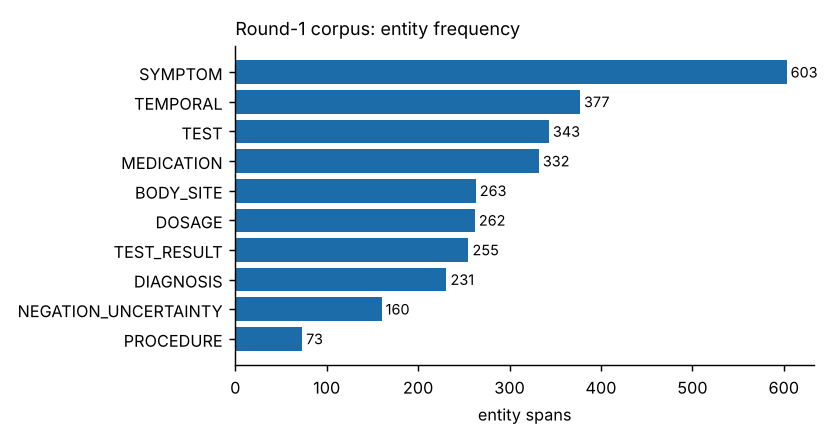

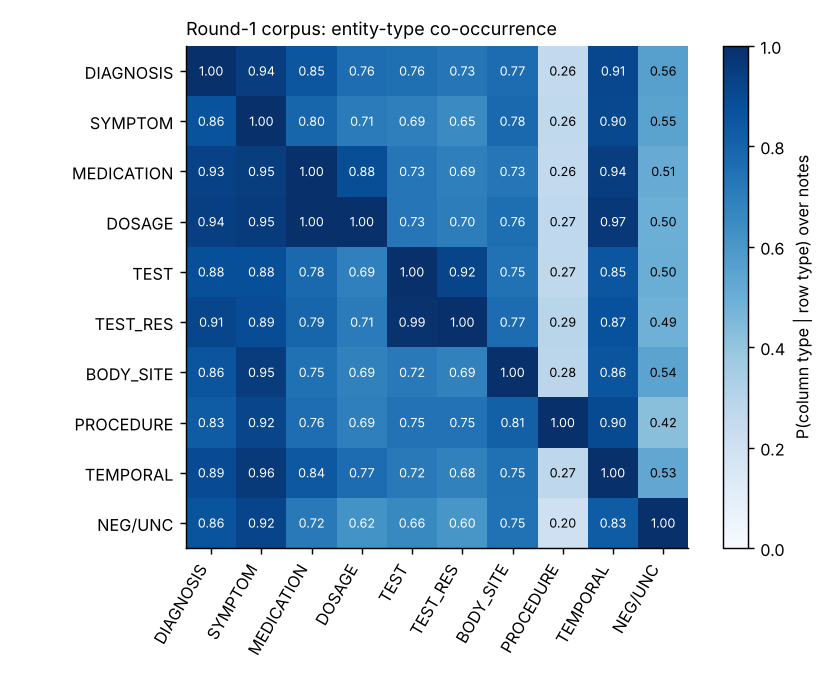

In [5]:
display(Image(str(OUT / "figures/eda_entity_frequency.png"), width=520))
display(Image(str(OUT / "figures/eda_cooccurrence.png"), width=560))

## 1 · NER — entity extraction

**Model.** Linear-chain CRF (`sklearn-crfsuite`, L-BFGS, c1 = c2 = 0.05) over rich features: word / prefix / suffix / shape, ±2 context, a hand-written
bilingual medical **gazetteer** (`src/medbhasha/lexicon.py`, general medical knowledge — *not* mined from the test notes) and **note-section context**
(the header group — `নির্ণয়:` / `Dx:`, `ব্যবস্থাপত্র:` / `Rx:`, `ভাইটাল সাইন:` … — is a very strong cue for the entity type).
Why not a transformer? With ≈ 12 k annotated tokens a fine-tuned encoder over-fits, and pretrained Bengali encoders cannot be downloaded in an offline, exactly-reproducible run.

**Evaluation (on our own data).** Entity-level micro P/R/F1 with `seqeval`. Two protocols: random 5-fold by note, and the harder *domain-held-out* 5-fold
(whole clinical specialties unseen at training time — a better proxy for unseen diseases/drugs in the hidden test set). Both are optimistic relative to the hidden test set
because the corpus is synthetic and written by one author (see *Limitations*).

In [6]:
t0 = time.time()
ner_eval = run_all.stage_ner_eval(fast=False)
print(f"{time.time()-t0:.0f}s")
display(ner_eval["cv"])

274s


,evaluation,model,precision,recall,f1
0,random 5-fold (by note),full: lexicon + section features,0.8883,0.8641,0.8760
1,random 5-fold (by note),no gazetteer lexicon,0.8662,0.8282,0.8468
2,random 5-fold (by note),no section features,0.8935,0.8620,0.8775
3,random 5-fold (by note),neither (plain CRF),0.8730,0.8251,0.8484
4,domain-held-out 5-fold,full: lexicon + section features,0.8733,0.8489,0.8609
5,domain-held-out 5-fold,no gazetteer lexicon,0.8362,0.7923,0.8137
6,domain-held-out 5-fold,no section features,0.8733,0.8413,0.8570
7,domain-held-out 5-fold,neither (plain CRF),0.8487,0.7799,0.8129


,precision,recall,f1-score,support
DIAGNOSIS,0.909,0.913,0.911,231.0
SYMPTOM,0.783,0.778,0.780,603.0
MEDICATION,0.929,0.901,0.914,332.0
DOSAGE,0.910,0.924,0.917,262.0
TEST,0.880,0.851,0.865,343.0
TEST_RESULT,0.892,0.808,0.848,255.0
BODY_SITE,0.760,0.745,0.752,263.0
PROCEDURE,0.844,0.740,0.788,73.0
TEMPORAL,0.970,0.936,0.953,377.0
NEGATION_UNCERTAINTY,0.927,0.869,0.897,160.0


,train_notes,train_tokens,precision,recall,f1
0,20,1065,0.8426,0.7755,0.8077
1,40,2055,0.8590,0.8082,0.8328
2,80,3973,0.8906,0.8469,0.8682
3,120,6055,0.8792,0.8612,0.8701
4,160,8306,0.9144,0.8939,0.9040
5,192,10058,0.9108,0.8959,0.9033


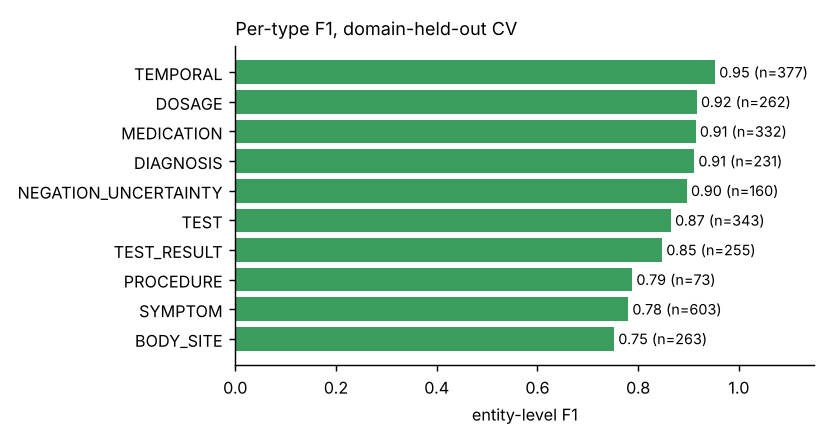

In [7]:
display(ner_eval["per_type"].round(3))
display(ner_eval["learning_curve"])
display(Image(str(OUT / "figures/ner_per_type_f1.png"), width=520))

### Train on the full corpus and predict the released (unlabeled) notes

In [8]:
pred = run_all.stage_ner_predict()
tdf, qdf = pipeline.load_test()
print(len(tdf), "released notes ->", len(pred["span_rows"]), "predicted entity spans;",
      f"{len(pred['span_rows'])/len(tdf):.1f} per note")
display(pred["freq"])

def show_pred(nid):
    rows = [r for r in pred["tok_rows"] if r[0] == nid]
    toks, tags = [r[1] for r in rows], [r[2] for r in rows]
    out, i = [], 0
    for s, e, ty in corpus.spans_from_bio(tags):
        out += toks[i:s]; out.append("[" + " ".join(toks[s:e]) + "]{" + ty + "}"); i = e
    return " ".join(out + toks[i:])
print(show_pred("MB-0301"))

1691 released notes -> 37619 predicted entity spans; 22.2 per note


,spans,distinct,notes,share_%
type,,,,
SYMPTOM,9097,535,1686,24.2
TEMPORAL,4962,132,1691,13.2
BODY_SITE,4930,246,1618,13.1
MEDICATION,4178,252,1656,11.1
TEST,3933,324,1351,10.5
DOSAGE,3404,212,1612,9.0
TEST_RESULT,2988,798,1111,7.9
DIAGNOSIS,2455,286,1486,6.5
NEGATION_UNCERTAINTY,1432,8,999,3.8


৪ বছর বয়সী মেয়ে শিশু । শিশুর মা জানান , [৪ দিন ধরে]{TEMPORAL} [জ্বর]{SYMPTOM} ও [গলায়]{BODY_SITE} [ব্যথা]{SYMPTOM} হচ্ছে , খেতে চাইছে না , গিলতে কান্না করছে , [মুখ]{BODY_SITE} দিয়ে লালা পড়ছে এবং [ঘাড়ে]{BODY_SITE} [ব্যথা]{SYMPTOM} ও [ফোলা]{SYMPTOM} আছে । পূর্ব ইতিহাস : টিকাদান সম্পূর্ণ । ভাইটাল সাইন : [তাপমাত্রা]{TEST} [৯৯.৫°F]{TEST_RESULT} , [নাড়ির গতি]{TEST} [১০৩/মিনিট]{TEST_RESULT} , [ওজন]{TEST} [১৬ কেজি]{TEST_RESULT} । পরীক্ষায় দেখা যায় : [টনসিল]{BODY_SITE} [লাল ও ফোলা]{SYMPTOM} , গায়ে [পুঁজ]{SYMPTOM} ; [গলা]{BODY_SITE} [লালচে]{SYMPTOM} । এছাড়া [গলার]{BODY_SITE} [সোয়াব কালচার]{TEST} করানোর পরামর্শ দেওয়া হয়েছে । রোগ নির্ণয় : [শিশুর টনসিলাইটিস]{DIAGNOSIS} । ব্যবস্থাপত্র : [অ্যামোক্সিসিলিন সিরাপ]{MEDICATION} [ওজন অনুযায়ী দিনে ৩ বার]{DOSAGE} [৭ দিন]{TEMPORAL} ; [প্যারাসিটামল সিরাপ]{MEDICATION} [ওজন অনুযায়ী জ্বরে প্রয়োজনে ৬ ঘণ্টা পরপর]{DOSAGE} ; কুসুম গরম তরল খাবার । পরামর্শ : ঠান্ডা খাবার ও পানীয় এড়ান । [অ্যান্টিবায়োটিক]{MEDICATION} পুরো কোর্স শেষ করুন । পুনরায় সাক

In [9]:
# stage_ner_predict() already ran the official validator on the prediction file
print(open(OUT / "ner_predictions_validation_report.txt", encoding="utf-8").read())

MedBhasha Annotation Validation Report

Result: PASS
Errors: 0
Warnings: 0




## 2 · Phenotype clustering (unsupervised)

Each note is represented **only by its predicted entities** (never by note id, file order or any label): (A) DIAGNOSIS mentions as character 2–4-gram TF-IDF
(robust to Bengali inflection/transliteration), (B) a typed bag of DIAGNOSIS / SYMPTOM / MEDICATION / TEST / PROCEDURE / BODY_SITE phrases (entity co-occurrence).
Both blocks are weighted equally, reduced with truncated SVD (64-d) and clustered. We compare k-means, Ward agglomerative and Louvain-on-a-kNN-graph and choose
**the algorithm and number of clusters by internal metrics only** (silhouette, Davies–Bouldin). No phenotype labels were used for selection.

chosen: {'algorithm': 'ward', 'k': 90} | internal scores: {'silhouette': 0.777, 'davies_bouldin': 0.717}
sanity check vs. the diagnosis line printed in each note (NOT the hidden gold): {'note': 'sanity check against the diagnosis line printed in the note (regex), NOT the hidden gold', 'notes_with_diagnosis_line': 1315, 'distinct_diagnosis_strings': 203, 'NMI': 0.905, 'ARI': 0.5652}


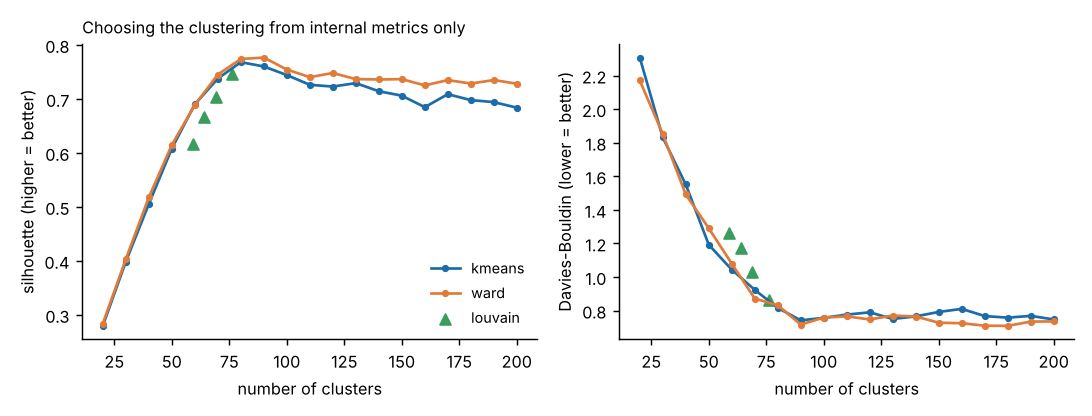

In [10]:
clu = run_all.stage_cluster(pred["span_rows"])
print("chosen:", clu["config"], "| internal scores:", {k: round(v, 3) for k, v in clu["scores"].items()})
print("sanity check vs. the diagnosis line printed in each note (NOT the hidden gold):", clu["proxy"])
display(Image(str(OUT / "figures/cluster_selection.png"), width=700))

In [11]:
s = clu["summary"]
print("clusters:", len(s), "| sizes: min", s["size"].min(), "median", int(s["size"].median()), "max", s["size"].max())
display(s[["cluster", "size", "top_diagnoses", "top_medications"]].head(12))

clusters: 90 | sizes: min 5 median 17 max 43


,cluster,size,top_diagnoses,top_medications
0,0,43,অ্যালার্জিক রাইনাইটিস (22); মৌসুমি অ্যালার্জিক রাইনাইটিস (10); অ্যালার্জি (7); শিশুর অ্যালার্জিক রাইনাইটিস (6); দীর্ঘস্থায়ী অ্যালার্জিক...,ফেক্সোফেনাডিন (15); ফ্লুটিকাসোন নাসাল স্প্রে (15); সিটিরিজিন সিরাপ (15); স্যালাইন নাসাল ড্রপ (15); মন্টেলুকাস্ট (14)
1,1,37,আর্টিকারিয়া (20); তীব্র আর্টিকারিয়া (13); আমবাত (6); শিশুর আমবাত (5),ক্যালামাইন লোশন (27); সিটিরিজিন সিরাপ (15); প্রেডনিসোলোন (10); লেভোসিটিরিজিন (10); ফেক্সোফেনাডিন (5)
2,2,36,তীব্র ওটাইটিস মিডিয়া (18); ওটাইটিস মিডিয়া (9); কানের সংক্রমণ (9); মধ্যকর্ণের সংক্রমণ (6); শিশুর কানের সংক্রমণ (4),অ্যামোক্সিসিলিন সিরাপ (17); প্যারাসিটামল সিরাপ (17); ইবুপ্রোফেন (10); সেফিক্সিম (10); অফলক্সাসিন কানের ড্রপ (9)
3,3,35,স্ক্যাবিস (35); খোসপাঁচড়া (14); শিশুর খোসপাঁচড়া (6); অ্যালার্জি (4); অ্যালার্জির ইতিহাস (1),পারমেথ্রিন (14); সিটিরিজিন সিরাপ (13); সিটিরিজিন (11); আইভারমেক্টিন (8); ক্যালামাইন লোশন চুলকানির (6)
4,4,34,ভাইরাল সংক্রমণজনিত জ্বর (11); তীব্র ভাইরাল ফিভার (10); ভাইরাল জ্বর (8); ম্যালেরিয়া (5); উচ্চ রক্তচাপ (4),প্যারাসিটামল (34); অ্যান্টিবায়োটিকের (25); সিটিরিজিন (23); ওআরএস (11)
5,5,33,গোড়ালিব্যথা (10); প্লান্টার ফ্যাসাইটিস (10); অ্যাঙ্কল স্প্রেন (5); গোড়ালির ব্যথা (5); গোড়ালি মচকানো (5),ডাইক্লোফেনাক জেল (33); প্যারাসিটামল (33); প্লান্টার ফ্যাসিয়া (9)
6,6,31,অ্যাটোপিক ডার্মাটাইটিস (18); ডার্মাটাইটিস (6); একজিমা (5); শিশুর একজিমা (4); দীর্ঘস্থায়ী একজিমা (3),হাইড্রোকর্টিসোন ১% ক্রিম (19); ইমোলিয়েন্ট ক্রিম (15); সিটিরিজিন সিরাপ (11); ইমোলিয়েন্ট লোশন (9); সিটিরিজিন (8)
7,7,31,টনসিলাইটিস (17); শিশুর টনসিলাইটিস (8); acute tonsillitis (4); অ্যালার্জি (4); তীব্র টনসিলাইটিস (4),প্যারাসিটামল (19); অ্যামোক্সিসিলিন সিরাপ (12); প্যারাসিটামল সিরাপ (12); অ্যান্টিবায়োটিকের (10); অ্যাজিথ্রোমাইসিন (7)
8,8,31,পেপটিক আলসার (14); epigastrium (13); গ্যাস্ট্রিক আলসার (7); ডিউডেনাল আলসার (6); পাকস্থলীর আলসার (5),ডাইক্লোফেনাক (24); ব্যথানাশক ট্যাবলেট (24); অ্যামোক্সিসিলিন (18); ইবুপ্রোফেন (18); ওমিপ্রাজল (18)
9,9,30,তীব্র ফ্যারিঞ্জাইটিস (10); ভাইরাল ফ্যারিঞ্জাইটিস (9); তীব্র ল্যারিঞ্জাইটিস (6); অ্যালার্জির ইতিহাস (3); ফ্যারিঞ্জাইটিস (3),প্যারাসিটামল (30); সিটিরিজিন (18); অ্যান্টিবায়োটিকের (14); কণ্ঠস্বরের সম্পূর্ণ (5)


### Frequency and relationship analysis on the NER output

,type,entity,count
0,DIAGNOSIS,ডায়াবেটিস,139
1,DIAGNOSIS,উচ্চ রক্তচাপ,120
2,DIAGNOSIS,অ্যালার্জি,114
3,DIAGNOSIS,অ্যালার্জির ইতিহাস,88
4,DIAGNOSIS,স্ক্যাবিস,35
5,SYMPTOM,ব্যথা,474
6,SYMPTOM,জ্বর,359
7,SYMPTOM,ফোলা,277
8,SYMPTOM,চুলকানি,241
9,SYMPTOM,জ্বালা,215


Top diagnosis → medication associations (co-occurrence over notes, lift, PMI):


,diagnosis,medication,co_notes,n_a,n_b,lift,pmi
0,তীব্র ল্যারিঞ্জাইটিস,কণ্ঠস্বরের সম্পূর্ণ,5,6,7,200.95,7.65
1,বসন্তকালীন অ্যালার্জিক চোখের প্রদাহ,ওলোপাটাডিন ০.১% আই ড্রপ,5,6,7,200.95,7.65
2,অ্যালার্জিক কনজাংটিভাইটিস,কিটোটিফেন ০.০৫% আই ড্রপ,5,9,5,187.56,7.55
3,এন্টেরোবিয়াসিস,আয়রন ও ফলিক অ্যাসিড সিরাপ,5,5,9,187.56,7.55
4,কৃমি,আয়রন ও ফলিক অ্যাসিড সিরাপ,5,5,9,187.56,7.55
5,শিশুর ত্বকের ব্যাকটেরিয়াল সংক্রমণ,মুপিরোসিন ২% মলম,5,5,9,187.56,7.55
6,মেলাজমা,ভিটামিন সি সিরাম,8,8,10,168.80,7.40
7,তীব্র অ্যালার্জিক প্রতিক্রিয়া,ফেনিরামিন ইনজেকশন,6,6,10,168.80,7.40
8,হাঁটুর বাত,গ্লুকোসামিন ও কনড্রয়েটিন সালফেট,6,9,7,160.76,7.33
9,মেলাজমা,ট্রেটিনোইন ০.০২৫% ক্রিম,8,8,11,153.45,7.26


Top diagnosis → symptom associations:


,diagnosis,symptom,co_notes,n_a,n_b,lift,pmi
0,ক্যাটারাক্ট,nuclear sclerosis,5,8,5,211.38,7.72
1,তীব্র ল্যারিঞ্জাইটিস,স্বর কর্কশ,5,6,7,201.31,7.65
2,সার্ভাইকাল স্পন্ডিলোসিস,অসাড়তা অনুভব,5,5,9,187.89,7.55
3,অস্টিওআর্থ্রাইটিস,কটকট,5,8,6,176.15,7.46
4,তীব্র গ্যাস্ট্রোএন্টেরাইটিস,hyperactive bowel sound,7,7,10,169.10,7.40
5,ফেসিয়াল নার্ভ প্যালসি,ভাঁজ,6,6,10,169.10,7.40
6,বারবার মুখের ঘা,সাদা-হলুদ ঘা,7,8,9,164.40,7.36
7,ইরিটেবল বাওয়েল সিন্ড্রোম,ওজন কমা,7,8,10,147.96,7.21
8,নিউমোনিয়া,হলুদ-সবুজ শ্লেষ্মা,7,10,8,147.96,7.21
9,বারবার মুখের ঘা,লসিকা গ্রন্থি ফোলা,7,8,10,147.96,7.21


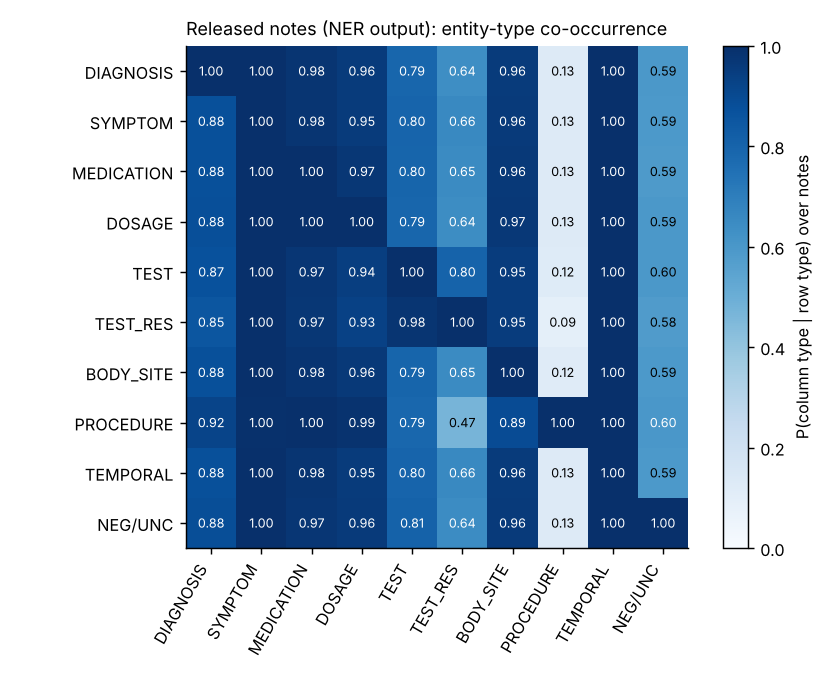

In [12]:
top = pd.read_csv(OUT / 'test_top_entities.csv')
display(top.groupby('type').head(5).reset_index(drop=True))
print("Top diagnosis → medication associations (co-occurrence over notes, lift, PMI):")
display(pred["dx_med"].head(12))
print("Top diagnosis → symptom associations:")
display(pred["dx_sym"].head(10))
display(Image(str(OUT / "figures/test_cooccurrence.png"), width=560))

## 3 · Retrieval-augmented question answering (no external API)

**Knowledge base.** Our annotated notes (gold spans) **+** the released notes annotated by *our own* NER model (predicted spans).
The queries ask for *patients* ("রোগীদের দেখান"), which only the released notes can answer; to respect the rule "retrieve from your own annotated corpus only"
we also write a strict **team-corpus-only** answer file (`rag_answers_team_corpus_only.*`). **Please pick the interpretation the organisers confirm** (see report §6.4).

**Retriever.** Spelling-skeleton + light Bengali stemming → BM25, a bilingual concept table (abbreviations, drug classes), negation/family-history-aware concept detection,
age/sex and numeric constraints (e.g. *HbA1c ৯-এর বেশি*). Notes satisfying **all** conditions rank first; otherwise the closest partial matches are shown and labelled.

**Generator.** Extractive and grounded: every sentence/entity in an answer is copied from a retrieved note and cited `[note-id]`; if nothing matches, the system says so instead of guessing.

In [13]:
rag = run_all.stage_rag(pred["span_rows"])
res = rag["rag_answers"]["results"]
display(res[["query_id", "query_text", "detected_concepts", "n_matched_notes", "n_partial_notes"]])

,query_id,query_text,detected_concepts,n_matched_notes,n_partial_notes
0,q01,ডায়াবেটিস রোগীদের জন্য কোন কোন ওষুধ নথিভুক্ত করা আছে?,diabetes,89,0
1,q02,নিউমোনিয়ায় আক্রান্ত রোগীদের ক্ষেত্রে কোন কোন উপসর্গ উল্লেখ করা আছে?,pneumonia,37,0
2,q03,হার্ট ফেইলিওর আছে এমন রোগীদের বর্ণনা দিন।,heart_failure,4,0
3,q04,হাঁপানি আছে ও রাতে কাশি হয় এমন রোগীদের জন্য কোন কোন ওষুধ নথিভুক্ত করা আছে?,"asthma, cough_night",34,0
4,q05,গাউট এবং সিরাম ইউরিক অ্যাসিড বেশি আছে এমন রোগীদের বর্ণনা দিন।,"gout, uric_acid",26,0
5,q06,উচ্চ রক্তচাপ ও ডায়াবেটিস আছে এমন রোগীদের মধ্যে কী কী ক্লিনিক্যাল ফাইন্ডিংস পাওয়া যায়?,"diabetes, hypertension",3,0
6,q07,কোন কোন রোগীর শ্বাসকষ্ট আছে?,dyspnea,190,0
7,q08,"পাতলা পায়খানা ও জল শূন্যতা আছে, ওআরএস নিচ্ছে এমন বাচ্চাদের দেখান।","dehydration, diarrhea, ors",23,0
8,q09,ডায়াবেটিক রোগীদের বিস্তারিত তথ্য এনে দিন।,diabetes,89,0
9,q10,"হার্ট ফেইলিওর, ডায়াবেটিস ও কিডনির সমস্যায় আক্রান্ত এবং লুপ ডাইইউরেটিক্স নিচ্ছেন এমন রোগীদের দেখান।","diabetes, heart_failure, loop_diuretic",1,3


In [14]:
for qid in ("q01", "q10", "q19", "q22"):
    row = res[res.query_id == qid].iloc[0]
    display(Markdown(f"**{qid}: {row.query_text}**\n\n```\n{row.answer}\n```"))

**q01: ডায়াবেটিস রোগীদের জন্য কোন কোন ওষুধ নথিভুক্ত করা আছে?**

```
নথিতে ৮৯ জন রোগীর নোট পাওয়া গেছে যেখানে প্রশ্নের সব শর্ত মিলেছে। এর মধ্যে ৩৫টিতে রোগটি নোটের নির্ণয় (Dx) অংশে আছে; সারসংক্ষেপ সেগুলোর ভিত্তিতে তৈরি।
নথিভুক্ত ওষুধ (কতগুলো নোটে): মেটফর্মিন (৩০টি নোট, [n048] [MB-0051] [MB-0371] [MB-0583] [MB-1154] [MB-0692] …); সিটাগ্লিপটিন (৯টি নোট, [MB-0371] [MB-0877] [n172] [MB-1250] [MB-0884] [MB-0732] …); ডাপাগ্লিফ্লোজিন (৮টি নোট, [MB-0051] [MB-0583] [MB-1154] [MB-0692] [MB-0067] [MB-0395] …); গ্লিমিপিরাইড (৮টি নোট, [MB-0938] [MB-0202] [MB-0251] [MB-0324] [MB-0385] [MB-0390] …); ইনসুলিন (৪টি নোট, [n006] [n192] [n054] [n049]); গ্লিমেপিরাইড (১টি নোট, [n048]); শিরায় স্যালাইন (১টি নোট, [n122]); ইনসুলিন ইনফিউশন (১টি নোট, [n122]); পটাসিয়াম (১টি নোট, [n122]); সিপ্রোফ্লক্সাসিন (১টি নোট, [n054])।
রোগীভিত্তিক বিবরণ (উৎস নোট সহ):
- [n048] ৫০ বছর, পুরুষ — রোগ নির্ণয়: টাইপ ২ ডায়াবেটিস মেলিটাস — ওষুধ: মেটফর্মিন ৫০০ মি.গ্রা. দিনে ২ বার খাবারের পর, গ্লিমেপিরাইড ১ মি.গ্রা. সকালে ১টি — নোট থেকে: «রোগ নির্ণয়: টাইপ ২ ডায়াবেটিস মেলিটাস»
- [MB-0051] ৭৬ বছর, মহিলা — রোগ নির্ণয়: টাইপ-২ ডায়াবেটিস মেলিটাস — ওষুধ: মেটফর্মিন ৫০০ মি.গ্রা. দিনে ২ বার, ডাপাগ্লিফ্লোজিন ১০ মি.গ্রা. সকালে ১টি — নোট থেকে: «পূর্ব ইতিহাস: ৫ বছর ধরে ডায়াবেটিসে ভুগছেন | প্রাথমিক নির্ণয়: টাইপ-২ ডায়াবেটিস মেলিটাস»
- [MB-0371] ৩৬ বছর, পুরুষ — রোগ নির্ণয়: অ্যালার্জি, টাইপ-২ ডায়াবেটিস মেলিটাস — ওষুধ: মেটফর্মিন ১০০০ মি.গ্রা. দিনে ২ বার, সিটাগ্লিপটিন ৫০ মি.গ্রা. দিনে ১টি — নোট থেকে: «Dx: টাইপ-২ ডায়াবেটিস মেলিটাস»
- [MB-0583] ৭৩ বছর, মহিলা — রোগ নির্ণয়: টাইপ-২ ডায়াবেটিস মেলিটাস — ওষুধ: মেটফর্মিন ৫০০ মি.গ্রা. দিনে ২ বার, ডাপাগ্লিফ্লোজিন ১০ মি.গ্রা. সকালে ১টি — নোট থেকে: «Dx: টাইপ-২ ডায়াবেটিস মেলিটাস»
- [MB-1154] ৩৭ বছর, মহিলা — রোগ নির্ণয়: ডায়াবেটিসের, টাইপ-২ ডায়াবেটিস মেলিটাস — ওষুধ: মেটফর্মিন ৫০০ মি.গ্রা. দিনে ২ বার, ডাপাগ্লিফ্লোজিন ১০ মি.গ্রা. সকালে ১টি — নোট থেকে: «নির্ণয়: টাইপ-২ ডায়াবেটিস মেলিটাস | ইতিহাস: পরিবারে ডায়াবেটিসের ইতিহাস আছে»
- [MB-0692] ৪৮ বছর, পুরুষ — রোগ নির্ণয়: টাইপ-২ ডায়াবেটিস মেলিটাস — ওষুধ: মেটফর্মিন ৫০০ মি.গ্রা. দিনে ২ বার, ডাপাগ্লিফ্লোজিন ১০ মি.গ্রা. সকালে ১টি — নোট থেকে: «Dx: টাইপ-২ ডায়াবেটিস মেলিটাস | H/O: ৫ বছর ধরে ডায়াবেটিসে ভুগছেন»
- [MB-0067] ৪৬ বছর, মহিলা — রোগ নির্ণয়: টাইপ-২ ডায়াবেটিস মেলিটাস — ওষুধ: মেটফর্মিন ৫০০ মি.গ্রা. দিনে ২ বার, ডাপাগ্লিফ্লোজিন ১০ মি.গ্রা. সকালে ১টি — নোট থেকে: «Dx: টাইপ-২ ডায়াবেটিস মেলিটাস»
- [MB-0877] ৪২ বছর, পুরুষ — রোগ নির্ণয়: টাইপ-২ ডায়াবেটিস মেলিটাস — ওষুধ: মেটফর্মিন ১০০০ মি.গ্রা. দিনে ২ বার, সিটাগ্লিপটিন ৫০ মি.গ্রা. দিনে ১টি — নোট থেকে: «Dx: টাইপ-২ ডায়াবেটিস মেলিটাস»
- … আরও ৮১টি মিলে যাওয়া নোট: [n172] [n006] [n192] [n122] [n222] [MB-0938] [MB-1250] [n054] [MB-0395] [MB-0911] [MB-0202] [MB-0251]
```

**q10: হার্ট ফেইলিওর, ডায়াবেটিস ও কিডনির সমস্যায় আক্রান্ত এবং লুপ ডাইইউরেটিক্স নিচ্ছেন এমন রোগীদের দেখান।**

```
নথিতে ১ জন রোগীর নোট পাওয়া গেছে যেখানে প্রশ্নের সব শর্ত মিলেছে।
রোগীভিত্তিক বিবরণ (উৎস নোট সহ):
- [n191] ৬৮ বছর, পুরুষ — রোগ নির্ণয়: হার্ট ফেইলিওর, টাইপ ২ ডায়াবেটিস, দীর্ঘস্থায়ী কিডনি রোগ — ওষুধ: ফিউরোসেমাইড ৮০ মি.গ্রা. সকালে ১টি, ইনসুলিন গ্লারজিন রাতে ১২ ইউনিট, কার্ভেডিলল দিনে ২ বার — নোট থেকে: «পূর্ব ইতিহাস: হার্ট ফেইলিওর, টাইপ ২ ডায়াবেটিস ও দীর্ঘস্থায়ী কিডনি রোগ | চিকিৎসা: ফিউরোসেমাইড ৮০ মি.গ্রা. সকালে ১টি»
আংশিক মিল (সব শর্ত নয়):
- [n055] ৬৫ বছর, পুরুষ — রোগ নির্ণয়: ডায়াবেটিস, উচ্চ রক্তচাপ, দীর্ঘস্থায়ী কিডনি রোগ — ওষুধ: ফিউরোসেমাইড ৪০ মি.গ্রা. সকালে ১টি, ক্যালসিয়াম দিনে ১ বার, NSAID — নোট থেকে: «চিকিৎসা: ফিউরোসেমাইড ৪০ মি.গ্রা. সকালে ১টি | পূর্ব ইতিহাস: ডায়াবেটিস ও উচ্চ রক্তচাপ ১৫ বছর ধরে» — মেলেনি: হার্ট ফেইলিওর
- [n043] ৭২ বছর, পুরুষ — রোগ নির্ণয়: হার্ট অ্যাটাক, হার্ট ফেইলিওর — ওষুধ: ফিউরোসেমাইড ৪০ মি.গ্রা. সকালে ১টি, ক্যারভেডিলল ৩.১২৫ মি.গ্রা. দিনে ২ বার, র‍্যামিপ্রিল ২.৫ মি.গ্রা. রাতে ১টি — নোট থেকে: «রোগ নির্ণয়: হার্ট ফেইলিওর | চিকিৎসা: ফিউরোসেমাইড ৪০ মি.গ্রা. সকালে ১টি» — মেলেনি: ডায়াবেটিস
- [n121] ৬৮ বছর, পুরুষ — রোগ নির্ণয়: হার্ট ফেইলিওর — ওষুধ: ফিউরোসেমাইড শিরায় ৪০ মি.গ্রা. দিনে ২ বার, স্পাইরোনোল্যাকটোন ২৫ মি.গ্রা. দিনে ১টি — নোট থেকে: «চূড়ান্ত নির্ণয়: হার্ট ফেইলিওর | চিকিৎসা: ফিউরোসেমাইড শিরায় ৪০ মি.গ্রা. দিনে ২ বার» — মেলেনি: ডায়াবেটিস
```

**q19: মেটফর্মিন চলছে এবং HbA1c ৯-এর বেশি এমন T2DM রোগী খুঁজুন।**

```
নথিতে ৮ জন রোগীর নোট পাওয়া গেছে যেখানে প্রশ্নের সব শর্ত মিলেছে।
রোগীভিত্তিক বিবরণ (উৎস নোট সহ):
- [n048] ৫০ বছর, পুরুষ — রোগ নির্ণয়: টাইপ ২ ডায়াবেটিস মেলিটাস — ওষুধ: মেটফর্মিন ৫০০ মি.গ্রা. দিনে ২ বার খাবারের পর, গ্লিমেপিরাইড ১ মি.গ্রা. সকালে ১টি — নোট থেকে: «খালি পেটে রক্তে শর্করা ১৮৫ মি.গ্রা./ডেসিলিটার, HbA1c ৯.২% | HbA1c ৩ মাস পর পুনরায় পরীক্ষা করুন»
- [n192] ৫২ বছর, পুরুষ — রোগ নির্ণয়: ডায়াবেটিস, অনিয়ন্ত্রিত টাইপ ২ ডায়াবেটিস — ওষুধ: মেটফর্মিন ১ গ্রাম দিনে ২ বার, ইনসুলিন রাতে ১০ ইউনিট — নোট থেকে: «HbA1c ১০.২%, খালি পেটে শর্করা ২১০ মি.গ্রা./ডেসিলিটার | HbA1c ৩ মাস পর»
- [MB-0051] ৭৬ বছর, মহিলা — রোগ নির্ণয়: টাইপ-২ ডায়াবেটিস মেলিটাস — ওষুধ: মেটফর্মিন ৫০০ মি.গ্রা. দিনে ২ বার, ডাপাগ্লিফ্লোজিন ১০ মি.গ্রা. সকালে ১টি — নোট থেকে: «HbA1c ৯.৪% | পূর্ব ইতিহাস: ৫ বছর ধরে ডায়াবেটিসে ভুগছেন»
- [MB-0583] ৭৩ বছর, মহিলা — রোগ নির্ণয়: টাইপ-২ ডায়াবেটিস মেলিটাস — ওষুধ: মেটফর্মিন ৫০০ মি.গ্রা. দিনে ২ বার, ডাপাগ্লিফ্লোজিন ১০ মি.গ্রা. সকালে ১টি — নোট থেকে: «HbA1c ১০.২% | Dx: টাইপ-২ ডায়াবেটিস মেলিটাস»
- [MB-0067] ৪৬ বছর, মহিলা — রোগ নির্ণয়: টাইপ-২ ডায়াবেটিস মেলিটাস — ওষুধ: মেটফর্মিন ৫০০ মি.গ্রা. দিনে ২ বার, ডাপাগ্লিফ্লোজিন ১০ মি.গ্রা. সকালে ১টি — নোট থেকে: «HbA1c ১০.১% | Dx: টাইপ-২ ডায়াবেটিস মেলিটাস»
- [MB-0877] ৪২ বছর, পুরুষ — রোগ নির্ণয়: টাইপ-২ ডায়াবেটিস মেলিটাস — ওষুধ: মেটফর্মিন ১০০০ মি.গ্রা. দিনে ২ বার, সিটাগ্লিপটিন ৫০ মি.গ্রা. দিনে ১টি — নোট থেকে: «HbA1c ৯.৫% | Dx: টাইপ-২ ডায়াবেটিস মেলিটাস»
- [MB-0911] ৬৬ বছর, পুরুষ — রোগ নির্ণয়: অনিয়ন্ত্রিত ডায়াবেটিস মেলিটাস — ওষুধ: মেটফর্মিন ৫০০ মি.গ্রা. দিনে ২ বার, ডাপাগ্লিফ্লোজিন ১০ মি.গ্রা. সকালে ১টি — নোট থেকে: «HbA1c ১০.৭% | H/O: ৫ বছর ধরে ডায়াবেটিসে ভুগছেন»
- [MB-0884] ৪৪ বছর, পুরুষ — রোগ নির্ণয়: ডায়াবেটিসের, টাইপ-২ ডায়াবেটিস — ওষুধ: মেটফর্মিন ১০০০ মি.গ্রা. দিনে ২ বার, সিটাগ্লিপটিন ৫০ মি.গ্রা. দিনে ১টি — নোট থেকে: «HbA1c ৯.১% | নির্ণয়: টাইপ-২ ডায়াবেটিস»
```

**q22: ভাইরাল জ্বরের কোন কোন রোগীকে বলা হয়েছে যে অ্যান্টিবায়োটিকের প্রয়োজন নেই?**

```
নথিতে ৫৪ জন রোগীর নোট পাওয়া গেছে যেখানে প্রশ্নের সব শর্ত মিলেছে। এর মধ্যে ৩৯টিতে রোগটি নোটের নির্ণয় (Dx) অংশে আছে; সারসংক্ষেপ সেগুলোর ভিত্তিতে তৈরি।
রোগীভিত্তিক বিবরণ (উৎস নোট সহ):
- [MB-1064] ৩১ বছর, মহিলা — রোগ নির্ণয়: অ্যালার্জির ইতিহাস, সাধারণ সর্দি-কাশি, কমন কোল্ড — ওষুধ: প্যারাসিটামল ৫০০ মি.গ্রা. প্রয়োজনে, সিটিরিজিন ১০ মি.গ্রা. রাতে ১টি, স্যালাইন নাসাল ড্রপ দিনে ৩ বার, অ্যান্টিবায়োটিকের — নোট থেকে: «Adv: অ্যান্টিবায়োটিকের প্রয়োজন নেই | Dx: সাধারণ সর্দি-কাশি (কমন কোল্ড)»
- [MB-0118] ২২ বছর, পুরুষ — রোগ নির্ণয়: সাধারণ সর্দি-কাশি — ওষুধ: প্যারাসিটামল ৫০০ মি.গ্রা. প্রয়োজনে, সিটিরিজিন ১০ মি.গ্রা. রাতে ১টি, স্যালাইন নাসাল ড্রপ দিনে ৩ বার, অ্যান্টিবায়োটিকের — নোট থেকে: «পরামর্শ: অ্যান্টিবায়োটিকের প্রয়োজন নেই | নির্ণয়: সাধারণ সর্দি-কাশি (কমন কোল্ড)»
- [MB-0190] ৫১ বছর, মহিলা — রোগ নির্ণয়: সাধারণ সর্দি-কাশি — ওষুধ: প্যারাসিটামল ৫০০ মি.গ্রা. প্রয়োজনে, সিটিরিজিন ১০ মি.গ্রা. রাতে ১টি, স্যালাইন নাসাল ড্রপ দিনে ৩ বার, অ্যান্টিবায়োটিকের — নোট থেকে: «উপদেশ: অ্যান্টিবায়োটিকের প্রয়োজন নেই | প্রাথমিক নির্ণয়: সাধারণ সর্দি-কাশি (কমন কোল্ড)»
- [MB-1119] ৩০ বছর, পুরুষ — রোগ নির্ণয়: সাধারণ সর্দি-কাশি — ওষুধ: প্যারাসিটামল ৫০০ মি.গ্রা. প্রয়োজনে, সিটিরিজিন ১০ মি.গ্রা. রাতে ১টি, স্যালাইন নাসাল ড্রপ দিনে ৩ বার, অ্যান্টিবায়োটিকের — নোট থেকে: «অ্যান্টিবায়োটিকের প্রয়োজন নেই | রোগ নির্ণয় করা হয়েছে: সাধারণ সর্দি-কাশি (কমন কোল্ড)»
- [MB-0997] ৪০ বছর, মহিলা — রোগ নির্ণয়: সাধারণ সর্দি-কাশি — ওষুধ: প্যারাসিটামল ৫০০ মি.গ্রা. প্রয়োজনে, সিটিরিজিন ১০ মি.গ্রা. রাতে ১টি, স্যালাইন নাসাল ড্রপ দিনে ৩ বার, অ্যান্টিবায়োটিকের — নোট থেকে: «অ্যান্টিবায়োটিকের প্রয়োজন নেই | রোগ নির্ণয়: সাধারণ সর্দি-কাশি (কমন কোল্ড)»
- [MB-0009] ৩৯ বছর, পুরুষ — রোগ নির্ণয়: ভাইরাল সংক্রমণজনিত জ্বর — ওষুধ: প্যারাসিটামল ৫০০ মি.গ্রা. প্রয়োজনে, সিটিরিজিন ১০ মি.গ্রা. রাতে ১টি, অ্যান্টিবায়োটিকের — নোট থেকে: «Adv: অ্যান্টিবায়োটিকের প্রয়োজন নেই | Dx: ভাইরাল সংক্রমণজনিত জ্বর»
- [MB-1121] ৩৩ বছর, পুরুষ — রোগ নির্ণয়: ম্যালেরিয়া, ভাইরাল সংক্রমণজনিত জ্বর — ওষুধ: প্যারাসিটামল ৫০০ মি.গ্রা. প্রয়োজনে, সিটিরিজিন ১০ মি.গ্রা. রাতে ১টি, অ্যান্টিবায়োটিকের — নোট থেকে: «পরামর্শ: অ্যান্টিবায়োটিকের প্রয়োজন নেই | নির্ণয়: ভাইরাল সংক্রমণজনিত জ্বর»
- [MB-0628] ২৬ বছর, মহিলা — রোগ নির্ণয়: ভাইরাল সংক্রমণজনিত জ্বর — ওষুধ: প্যারাসিটামল ৫০০ মি.গ্রা. প্রয়োজনে, সিটিরিজিন ১০ মি.গ্রা. রাতে ১টি, অ্যান্টিবায়োটিকের — নোট থেকে: «পরামর্শ: অ্যান্টিবায়োটিকের প্রয়োজন নেই | ডায়াগনোসিস: ভাইরাল সংক্রমণজনিত জ্বর»
- … আরও ৪৬টি মিলে যাওয়া নোট: [MB-0042] [MB-1231] [MB-0617] [MB-0614] [MB-0941] [MB-0310] [MB-0609] [MB-0305] [MB-1204] [MB-1021] [MB-1218] [MB-0117]
```

### Live query (finale) — type any Bengali question. The example uses the synonym *অ্যাজমা* = *হাঁপানি* and the *children* constraint.

In [15]:
from medbhasha.ask import ask
R = rag["rag_answers"]["retriever"]
out = ask(R, "অ্যাজমা আছে এমন শিশুদের কী ওষুধ দেওয়া হয়েছে?")
print(out["answer"]); print("\nretrieved:", out["retrieved"])

নথিতে ১৬ জন রোগীর নোট পাওয়া গেছে যেখানে প্রশ্নের সব শর্ত মিলেছে। এর মধ্যে ১০টিতে রোগটি নোটের নির্ণয় (Dx) অংশে আছে; সারসংক্ষেপ সেগুলোর ভিত্তিতে তৈরি।
রোগীভিত্তিক বিবরণ (উৎস নোট সহ):
- [MB-1071] ৫ বছর, পুরুষ — রোগ নির্ণয়: শিশুদের হাঁপানি — ওষুধ: সালবিউটামল ইনহেলার স্পেসারসহ প্রয়োজনে ২ পাফ, বুডেসোনাইড ইনহেলার স্পেসারসহ দিনে ২ বার, মন্টেলুকাস্ট, ট্যাবলেট ৪/৫ মি.গ্রা. — নোট থেকে: «নির্ণয়: শিশুদের হাঁপানি»
- [MB-0336] ৫ বছর, মহিলা — রোগ নির্ণয়: শিশুর ব্রংকিয়াল অ্যাজমা — ওষুধ: সালবিউটামল ইনহেলার স্পেসারসহ প্রয়োজনে ২ পাফ, বুডেসোনাইড ইনহেলার স্পেসারসহ দিনে ২ বার — নোট থেকে: «নির্ণয়: শিশুর ব্রংকিয়াল অ্যাজমা»
- [MB-0647] ১২ বছর, পুরুষ — রোগ নির্ণয়: শিশুর ব্রংকিয়াল অ্যাজমা — ওষুধ: সালবিউটামল ইনহেলার স্পেসারসহ প্রয়োজনে ২ পাফ, বুডেসোনাইড ইনহেলার স্পেসারসহ দিনে ২ বার, মন্টেলুকাস্ট, ট্যাবলেট ৪/৫ মি.গ্রা. — নোট থেকে: «নির্ণয়: শিশুর ব্রংকিয়াল অ্যাজমা»
- [MB-0006] ৭ বছর, পুরুষ — রোগ নির্ণয়: শিশুদের হাঁপানি — ওষুধ: সালবিউটামল ইনহেলার স্পেসারসহ প্রয়োজনে ২ পাফ, বুডেসোনাইড ইনহেলার স্পেসারসহ 

In [16]:
# strict "team corpus only" variant for the same query (kept for rule compliance)
R_team = rag["rag_answers_team_corpus_only"]["retriever"]
print(ask(R_team, "অ্যাজমা আছে এমন শিশুদের কী ওষুধ দেওয়া হয়েছে?")["answer"])

নথিতে ১ জন রোগীর নোট পাওয়া গেছে যেখানে প্রশ্নের সব শর্ত মিলেছে।
রোগীভিত্তিক বিবরণ (উৎস নোট সহ):
- [n129] ১২ বছর, পুরুষ — রোগ নির্ণয়: তীব্র হাঁপানির আক্রমণ — ওষুধ: সালবিউটামল, হাইড্রোকর্টিসোন শিরায়, প্রিভেন্টার ইনহেলার — নোট থেকে: «চূড়ান্ত নির্ণয়: তীব্র হাঁপানির আক্রমণ»


## 4 · Reproducibility
Every output file is hashed in `outputs/run_manifest.json` (with library versions). Running the notebook (or `python scripts/run_pipeline.py`) twice, even with different
`PYTHONHASHSEED`, yields identical hashes — verified by `python scripts/check_reproducibility.py`.

In [17]:
man = run_all.write_manifest()
print({k: man[k] for k in ("python", "seed")}); print(man["versions"])
for k, v in list(man["output_md5"].items())[:40]:
    print(f"{v}  {k}")

{'python': '3.13.18', 'seed': 42}
{'numpy': '2.5.4', 'pandas': '3.1.1', 'scikit-learn': '1.9.1', 'scipy': '1.18.1', 'sklearn-crfsuite': '0.5.0', 'python-crfsuite': '0.9.12', 'seqeval': '1.2.2', 'networkx': '3.7', 'matplotlib': '3.11.2'}
3fa58eaf4bd2bed6a391ded43338db0a  cluster_config.json
30c6f3d6cdbbbd6455e6c82d2167e6dd  cluster_selection.csv
f4e80f82de9be3c2861eda78dfd02a6a  cluster_summary.csv
5ededdf5aeb53b606da8c9968aa165da  clusters.csv
00037293dedbd86ff2063c6d4fb70e4d  eda_cooccurrence.csv
6071a405edf2c3bf7bfe596feefc565f  eda_diagnosis_medication_pairs.csv
8c6e19b6460c8239cc8f0d13068b42bb  eda_domain_counts.csv
9a3907078519715de6e8ab254535201c  eda_entity_frequency.csv
f02b58eb04ac45e5be0f99bc7a73eabb  eda_top_entities.csv
198f04da13e0adbfb81ec683470d525a  ner_cv_per_type_domain_heldout.csv
8a0e990ca7ecfff139f522cd3c542f50  ner_cv_results.csv
3a2434ba66a0f96e2b3ef4965986edb4  ner_learning_curve.csv
4429b0eeafa555aec11541d6e7ce624d  ner_predictions.jsonl
241770549816b4d3a58fca7

## 5 · Limitations (honest summary)
* **Synthetic, single-author training data** → our cross-validated F1 (≈ 0.87) is an *upper bound*; the hidden gold may follow different span conventions (e.g. whether units belong to `TEST_RESULT`).
* No clinician has reviewed the annotations; no inter-annotator agreement exists.
* The RAG "generator" is extractive (templates + verbatim excerpts); fluent abstractive answers would need a local LLM, which cannot be shipped for an offline exact-reproducibility run.
* The concept table (`concepts.py`) was written with the public query set in view; unseen concepts fall back to BM25 + fuzzy stems (tested on unseen queries in the report).
* Clustering granularity (≈ 80–90 clusters) is chosen by internal metrics; the number of hidden phenotype classes is unknown.